# 04 · Do que o salário depende

Experiência, modelo de trabalho, estado, escolaridade e gênero — **cada um
com o resto fixo**. Regressão por intervalo (`salarios/estatistica.py`) sobre
quem não é gestor, edições de 2021 a 2025 juntas, com o ano como controle e
valores em reais de novembro de 2025.

Cada efeito é **quanto a mais (ou a menos) ganha alguém igual em todo o
resto**: mesmo cargo, nível, experiência, estado, escolaridade, porte de
empresa, vínculo e ano. É uma associação, não uma causa — quem trabalha
remoto não é sorteado; os controles tiram o que dá para medir, e o que não
dá para medir (habilidade, rede de contatos, empresa específica) fica.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from salarios.estatistica import RegressaoIntervalar
from salarios.graficos import AZUL, LARANJA, NIVEIS, TINTA_2, MUDO, estilo
from salarios.ipca import fator

estilo()
df = pd.read_parquet("../dados/tratados/respostas.parquet")
br = df[(df["situacao"] != "Fora do Brasil") & df["sal_min"].notna()].copy()
f = br["ano"].map(fator)
br["sal_min"], br["sal_max"] = br["sal_min"] * f, br["sal_max"] * f

VINCULOS = ["CLT", "PJ / Empreendedor", "Servidor público", "No Brasil, para empresa de fora", "Freelancer", "Estágio"]
d = br[(br["ano"] >= 2021) & br["familia"].notna() & (br["familia"] != "Gestor") & br["situacao"].isin(VINCULOS)].copy()
d["ano_c"] = d["ano"].astype(str)
d["genero_b"] = d["genero"].astype(str).where(d["genero"].isin(["Masculino", "Feminino"]))
ufs_grandes = [u for u, n in d["uf"].value_counts().items() if n >= 150 and u != "Exterior"]
d["uf_grupo"] = d["uf"].astype(str).where(d["uf"].isin(ufs_grandes), "outros estados")
d = d.dropna(subset=["exp_faixa", "ensino", "modelo", "porte", "genero_b", "nivel_comparavel"])
print(f"{len(d):,} respostas; estados com 150 ou mais: {', '.join(sorted(ufs_grandes))}")

14,640 respostas; estados com 150 ou mais: BA, CE, DF, ES, GO, MG, PB, PE, PR, RJ, RS, SC, SP


In [2]:
REF = {"modelo": "Presencial", "uf_grupo": "SP", "ensino": "Graduação", "genero_b": "Masculino",
       "porte": "101–500", "situacao": "CLT", "exp_faixa": "1 a 3 anos"}


def termo(var):
    return f"C({var}, Treatment('{REF[var]}'))" if var in REF else f"C({var})"


CONTROLES = ["ano_c", "familia", "nivel_comparavel", "exp_faixa", "modelo", "uf_grupo", "ensino", "genero_b", "porte", "situacao"]


def ajustar(dados, variaveis):
    return RegressaoIntervalar(" + ".join(termo(v) for v in variaveis), dados).ajustar()


def efeito(m, var, nivel):
    e = m.efeitos()
    return e.loc[f"{termo(var)}[T.{nivel}]"]


completo = ajustar(d, CONTROLES)
print(f"σ do log do salário: {completo.sigma:.3f}")

σ do log do salário: 0.376


## Os fatores, lado a lado

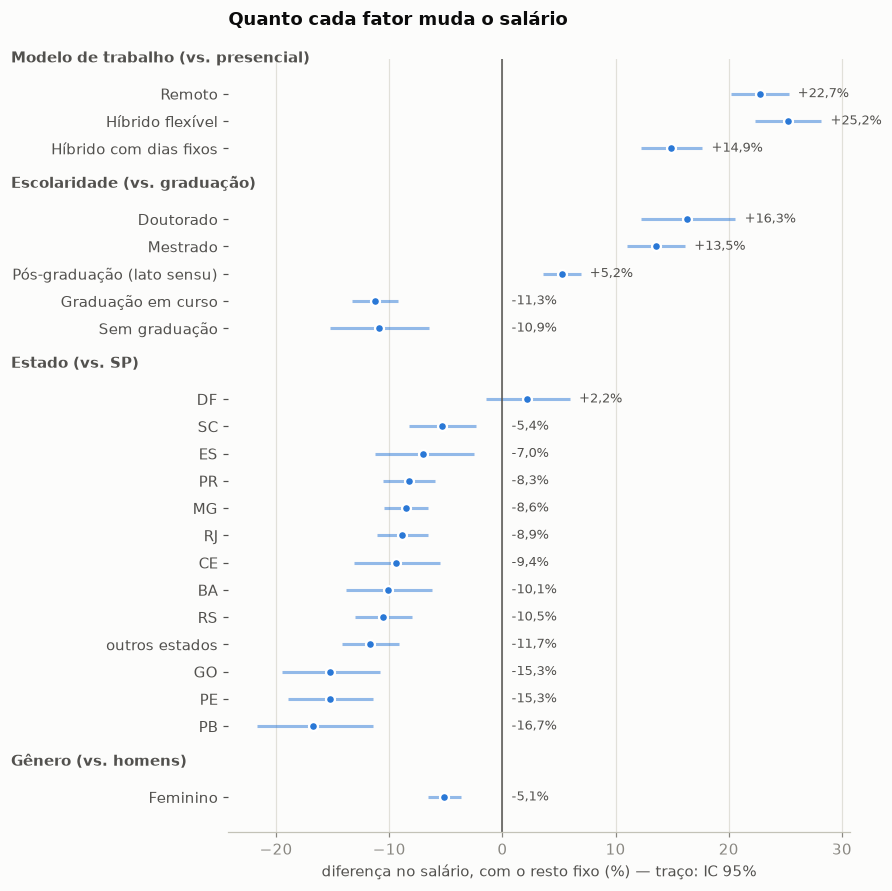

In [3]:
GRUPOS = {
    "Modelo de trabalho (vs. presencial)": ("modelo", ["Remoto", "Híbrido flexível", "Híbrido com dias fixos"]),
    "Escolaridade (vs. graduação)": ("ensino", ["Doutorado", "Mestrado", "Pós-graduação (lato sensu)", "Graduação em curso", "Sem graduação"]),
    "Estado (vs. SP)": ("uf_grupo", ["DF", "SC", "ES", "PR", "MG", "RJ", "CE", "BA", "RS", "outros estados", "GO", "PE", "PB"]),
    "Gênero (vs. homens)": ("genero_b", ["Feminino"]),
}
linhas = []
for grupo, (var, niveis) in GRUPOS.items():
    for n in niveis:
        r = efeito(completo, var, n)
        linhas.append({"grupo": grupo, "nivel": n, **r.to_dict()})
fat = pd.DataFrame(linhas)

fig, ax = plt.subplots(figsize=(8.5, 8.2))
y, ticks, rotulos = 0, [], []
for grupo, g in fat.groupby("grupo", sort=False):
    ax.annotate(grupo, (-0.35, y + 0.15), xycoords=("axes fraction", "data"), fontweight="bold", color=TINTA_2, fontsize=9.5)
    y -= 1
    for _, r in g.iterrows():
        ax.hlines(y, r["ic_baixo"] * 100, r["ic_alto"] * 100, color=AZUL, alpha=0.5, linewidth=2)
        ax.scatter(r["efeito"] * 100, y, color=AZUL, s=34, zorder=3, edgecolor="white", linewidth=1.5)
        ax.annotate(f"{r['efeito']:+.1%}".replace(".", ","), (max(r["ic_alto"] * 100, 0), y), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=8.5, color=TINTA_2)
        ticks.append(y); rotulos.append(r["nivel"])
        y -= 1
    y -= 0.6
ax.axvline(0, color=TINTA_2, linewidth=1)
ax.set_yticks(ticks, rotulos)
ax.grid(axis="y", visible=False)
ax.set_xlabel("diferença no salário, com o resto fixo (%) — traço: IC 95%")
ax.set_title("Quanto cada fator muda o salário", pad=22)
plt.tight_layout()

## Experiência: onde a curva achata

Nível e experiência andam juntos: com o nível no modelo, a experiência mede
só o que ela acrescenta **dentro** do mesmo nível. Sem o nível, mede o
efeito total de ter mais anos — inclusive o de ser promovido.

,Efeito total (sem controlar o nível),Dentro do mesmo nível
Sem experiência,-4.7,-8.3
Menos de 1 ano,-15.8,-7.6
1 a 3 anos,0.0,0.0
3 a 6 anos,43.4,14.2
6 a 10 anos,77.6,25.0
Mais de 10 anos,88.1,30.7


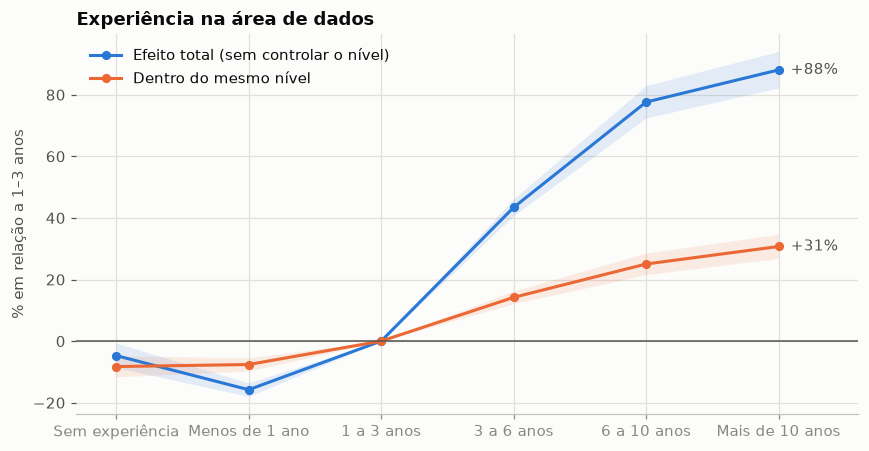

In [4]:
ORDEM_EXP = ["Sem experiência", "Menos de 1 ano", "1 a 3 anos", "3 a 6 anos", "6 a 10 anos", "Mais de 10 anos"]
sem_nivel = ajustar(d, [v for v in CONTROLES if v != "nivel_comparavel"])


def curva(m):
    return pd.DataFrame([efeito(m, "exp_faixa", n) if n != REF["exp_faixa"] else pd.Series({"efeito": 0.0, "ic_baixo": 0.0, "ic_alto": 0.0})
                         for n in ORDEM_EXP], index=ORDEM_EXP)


curvas = {"Efeito total (sem controlar o nível)": (curva(sem_nivel), AZUL),
          "Dentro do mesmo nível": (curva(completo), LARANJA)}
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(ORDEM_EXP))
for nome, (c, cor) in curvas.items():
    ax.fill_between(x, c["ic_baixo"] * 100, c["ic_alto"] * 100, color=cor, alpha=0.12, linewidth=0)
    ax.plot(x, c["efeito"] * 100, marker="o", markersize=5, color=cor, label=nome)
    ax.annotate(f"{c['efeito'].iloc[-1]:+.0%}", (x[-1], c["efeito"].iloc[-1] * 100), xytext=(8, 0),
                textcoords="offset points", va="center", color=TINTA_2)
ax.axhline(0, color=TINTA_2, linewidth=1)
ax.set_xticks(x, ORDEM_EXP)
ax.set_xlim(-0.3, len(ORDEM_EXP) - 0.4)
ax.set_ylabel("% em relação a 1–3 anos")
ax.set_title("Experiência na área de dados")
ax.legend(loc="upper left")
plt.tight_layout()
pd.DataFrame({nome: (c["efeito"] * 100).round(1) for nome, (c, _) in curvas.items()})

- **Efeito total:** quem tem de 6 a 10 anos ganha 78% a mais que quem tem de
  1 a 3, e quem tem mais de 10 anos, 88% a mais. **A curva achata depois dos
  6 anos:** de "6 a 10" para "mais de 10" são só 6% a mais.
- **Dentro do mesmo nível**, a experiência ainda paga: mais de 10 anos vale
  31% a mais que 1 a 3 anos para quem tem o mesmo cargo e o mesmo nível. A
  maior parte do ganho de experiência, porém, vem pela promoção.
- Um detalhe estranho: quem declara **não ter experiência em dados** ganha
  mais (−5%) do que quem tem menos de um ano (−16%). Hipótese, não
  verificada aqui: "sem experiência em dados" inclui quem já trabalha em
  outra área (desenvolvimento, negócios) e chega com o salário de lá.

## Remoto: quanto, e para quem

In [5]:
def por_grupo(col, valores, variaveis):
    linhas = {}
    for v in valores:
        g = d[d[col] == v]
        m = ajustar(g, variaveis)
        linhas[v] = {**{k: efeito(m, "modelo", "Remoto")[k] for k in ["efeito", "ic_baixo", "ic_alto"]}, "n": m.n}
    return pd.DataFrame(linhas).T


remoto_nivel = por_grupo("nivel_comparavel", ["Júnior", "Pleno", "Sênior"], [v for v in CONTROLES if v != "nivel_comparavel"])
remoto_ano = por_grupo("ano", [2021, 2022, 2023, 2024, 2025], [v for v in CONTROLES if v != "ano_c"])
so_clt = ajustar(d[d["situacao"] == "CLT"], [v for v in CONTROLES if v != "situacao"])
fmt = lambda t: t.assign(n=t["n"].astype(int), **{c: (t[c] * 100).round(1) for c in ["efeito", "ic_baixo", "ic_alto"]})
print("remoto vs presencial, só CLT: {:+.1%}".format(efeito(so_clt, "modelo", "Remoto")["efeito"]))
pd.concat({"por nível": fmt(remoto_nivel), "por ano": fmt(remoto_ano)})

remoto vs presencial, só CLT: +24.3%


efeito  ic_baixo  ic_alto     n
por nível Júnior    14.4      10.3     18.7  3987
          Pleno     21.5      17.5     25.6  5143
          Sênior    35.4      30.3     40.7  5510
por ano   2021      21.8      14.4     29.7  1822
          2022      20.5      14.8     26.4  2902
          2023      20.4      15.7     25.2  3779
          2024      24.8      19.9     29.8  3725
          2025      24.4      18.5     30.6  2412

**Remoto paga 23% a mais que presencial**, com o resto fixo, e o número é
estável: entre +20% e +25% em cada um dos cinco anos, e +24% olhando só
CLT. O efeito cresce com a senioridade — **+14% no júnior, +35% no
sênior**. O híbrido flexível paga como o remoto (+25%); o híbrido com dias
fixos fica no meio (+15%).

O que isso não diz: que mudar para o remoto aumenta o salário. Vagas
remotas tendem a estar em empresas que pagam mais e contratam de qualquer
lugar; porte e vínculo estão controlados, a empresa em si não está.

## Estado: Minas, São Paulo e o resto

Com o resto fixo, **Minas Gerais paga 8,6% menos que São Paulo** (IC −10,5%
a −6,6%), no mesmo patamar de Rio de Janeiro (−8,9%) e Paraná (−8,3%). O DF
é o único com estimativa igual ou acima de SP (+2,2%, sem diferença
estatística). No Nordeste a diferença vai de −9% (Ceará) e −10% (Bahia) a
−17% (Paraíba). Juiz de Fora ou BH não dá para separar: a pesquisa publica só a
UF.

## Escolaridade

Em relação a quem tem graduação, e com o resto fixo: pós lato sensu +5,2%,
**mestrado +13,5%, doutorado +16,3%**; sem graduação −10,9%, e quem ainda
está na graduação −11,3%.

## Gênero

In [6]:
genero = {}
for nome, variaveis in {
    "bruta (só o ano)": ["ano_c", "genero_b"],
    "cargo e nível": ["ano_c", "familia", "nivel_comparavel", "genero_b"],
    "todos os controles": CONTROLES,
}.items():
    genero[nome] = efeito(ajustar(d, variaveis), "genero_b", "Feminino")
genero = pd.DataFrame(genero).T.mul(100).round(1)
genero

,efeito,ic_baixo,ic_alto
bruta (só o ano),-11.7,-14.1,-9.3
cargo e nível,-2.7,-4.5,-0.9
todos os controles,-5.1,-6.6,-3.7


In [7]:
def genero_por(col, valores, variaveis):
    linhas = {}
    for v in valores:
        m = ajustar(d[d[col] == v], variaveis)
        linhas[v] = {**(efeito(m, "genero_b", "Feminino")[["efeito", "ic_baixo", "ic_alto"]] * 100).round(1).to_dict(), "n": m.n}
    return pd.DataFrame(linhas).T.assign(n=lambda t: t["n"].astype(int))


pd.concat({
    "por nível": genero_por("nivel_comparavel", ["Júnior", "Pleno", "Sênior"], [v for v in CONTROLES if v != "nivel_comparavel"]),
    "por ano": genero_por("ano", [2021, 2022, 2023, 2024, 2025], [v for v in CONTROLES if v != "ano_c"]),
})

efeito  ic_baixo  ic_alto     n
por nível Júnior    -4.9      -7.6     -2.1  3987
          Pleno     -2.6      -5.0     -0.2  5143
          Sênior    -8.2     -10.4     -5.8  5510
por ano   2021      -1.1      -5.8      3.7  1822
          2022      -6.5      -9.6     -3.3  2902
          2023      -4.9      -7.6     -2.1  3779
          2024      -5.3      -8.0     -2.5  3725
          2025      -6.6     -10.1     -2.9  2412

In [8]:
(d.groupby("genero_b")["ensino"].apply(lambda s: s.isin(["Mestrado", "Doutorado"]).mean())
   .mul(100).round(1).rename("% com mestrado ou doutorado"))

genero_b
Feminino     18.7
Masculino    13.6
Name: % com mestrado ou doutorado, dtype: float64

- **Diferença bruta: mulheres ganham 11,7% menos.** Com cargo e nível fixos,
  cai para 2,7%. Com todos os controles, **volta a subir, para 5,1%** (IC
  −6,6% a −3,7%).
- A diferença cresce com os controles porque as mulheres da amostra têm
  características que pagam mais: 18,7% delas têm mestrado ou doutorado,
  contra 13,6% dos homens. Comparando com homens de mesma escolaridade, a
  diferença aparece maior.
- **É maior entre sêniores (−8,2%)** e não aparece em 2021 (−1,1%, IC cruza
  o zero); de 2022 a 2025 fica entre −5% e −7%.

Cuidado na leitura: controlar cargo e nível pode **esconder** parte da
diferença, se as próprias promoções forem desiguais. Os −5,1% são a
diferença entre pessoas que já chegaram ao mesmo lugar.

## Os outros controles

Porte e vínculo entram para não confundir os fatores acima, mas têm efeitos
grandes por si:

In [9]:
outros = []
for var, niveis in {"porte": ["1–10", "11–100", "501–3.000", "Acima de 3.000"],
                    "situacao": ["No Brasil, para empresa de fora", "Servidor público", "PJ / Empreendedor", "Freelancer", "Estágio"]}.items():
    for n in niveis:
        outros.append({"fator": var, "nivel": n, **(efeito(completo, var, n) * 100).round(1).to_dict()})
pd.DataFrame(outros).set_index(["fator", "nivel"])

efeito  ic_baixo  ic_alto
fator    nivel                                                     
porte    1–10                              -25.7     -28.8    -22.4
         11–100                             -7.8      -9.9     -5.6
         501–3.000                           7.1       4.9      9.3
         Acima de 3.000                     12.3      10.3     14.4
situacao No Brasil, para empresa de fora   125.9     117.2    134.9
         Servidor público                   33.8      28.9     38.9
         PJ / Empreendedor                  16.1      13.3     19.1
         Freelancer                        -12.3     -18.1     -6.1
         Estágio                           -52.9     -54.5    -51.3

**Morar no Brasil e trabalhar para empresa de fora paga 126% a mais** que
CLT, o maior efeito de todo o modelo — 94% dessas pessoas trabalham remoto.
Servidor público ganha 34% a mais e PJ, 16% (bruto de PJ não desconta
benefícios nem impostos que o CLT tem descontados, então não é comparação
de renda líquida). Empresa com até 10 pessoas paga 26% menos que uma de 101
a 500; acima de 3.000, 12% a mais.